In [2]:

import pandas as pd

eatd = pd.read_csv("eatd.csv")
daic = pd.read_csv("data/daicwoz.csv")

print("=== EATD Dataset ===")
print("Total samples:", len(eatd))
print("Average words:", round(eatd["text"].str.split().str.len().mean(), 2))

print("\n=== DAIC-WOZ Dataset ===")
print("Total participants:", len(daic))
print("Average words:", round(daic["n_words"].mean(), 2))
print("Participant 440 included:", 440 in daic["id"].values)

display(daic.head())


=== EATD Dataset ===
Total samples: 162
Average words: 97.31

=== DAIC-WOZ Dataset ===
Total participants: 189
Average words: 1445.19
Participant 440 included: True


,id,label,split,text,n_words
0,303,0,train,okay how 'bout yourself here in california yea...,1960
1,304,0,train,i'm doing good um from los angeles california ...,976
2,305,0,train,i'm doing alright uh originally i'm from calif...,3321
3,310,0,train,yes it's okay fine i live in hollywood uh seat...,1069
4,312,0,train,yes fine how about you here yes the weather we...,1192


In [3]:

daic_sample = pd.read_csv(
    "all_csv_nlp/369_TRANSCRIPT.csv",
    sep="\t"
)

print("=== DAIC-WOZ ===")
print("Shape:", daic_sample.shape)
print("Columns:", daic_sample.columns.tolist())

display(daic_sample.head(10))

print("\nSpeakers:")
print(daic_sample["speaker"].value_counts())


=== DAIC-WOZ ===
Shape: (288, 4)
Columns: ['start_time', 'stop_time', 'speaker', 'value']


,start_time,stop_time,speaker,value
0,16.445,17.330,Participant,<sync>
1,35.005,35.480,Participant,<ellie starts>
2,35.077,56.617,Ellie,IntroV4Confirmation (hi i'm ellie thanks for c...
3,56.870,58.235,Participant,sure yeah
4,58.776,59.236,Ellie,okay_confirm (okay)
5,61.008,63.278,Ellie,how_doingV (so how are you doing today)
6,63.540,66.280,Participant,i'm doing great thank you for asking um
7,66.728,68.333,Participant,you know how about yourself
8,68.473,69.278,Participant,<laughter>
9,69.044,70.554,Ellie,great_thanks (i'm great thanks)



Speakers:
speaker
Participant    220
Ellie           68
Name: count, dtype: int64


In [4]:

import re
from collections import Counter

def tokenize(text):
    return re.findall(r"\b[a-z]+(?:'[a-z]+)?\b", str(text).lower())

def vocabulary_stats(df):
    tokens = []
    for text in df["text"].fillna(""):
        tokens.extend(tokenize(text))

    counts = Counter(tokens)

    return {
        "Total Tokens": len(tokens),
        "Unique Words": len(counts),
        "Type-Token Ratio": (
            len(counts) / len(tokens) if tokens else 0
        ),
        "Top 10 Words": counts.most_common(10)
    }

eatd_stats = vocabulary_stats(eatd)
daic_stats = vocabulary_stats(daic)

summary = pd.DataFrame([
    {
        "Dataset": "EATD",
        "Total Tokens": eatd_stats["Total Tokens"],
        "Unique Words": eatd_stats["Unique Words"],
        "TTR": eatd_stats["Type-Token Ratio"]
    },
    {
        "Dataset": "DAIC-WOZ",
        "Total Tokens": daic_stats["Total Tokens"],
        "Unique Words": daic_stats["Unique Words"],
        "TTR": daic_stats["Type-Token Ratio"]
    }
])

display(summary)

print("\nEATD Top 10 Words:")
print(eatd_stats["Top 10 Words"])

print("\nDAIC-WOZ Top 10 Words:")
print(daic_stats["Top 10 Words"])


,Dataset,Total Tokens,Unique Words,TTR
0,EATD,15937,1902,0.119345
1,DAIC-WOZ,272875,8127,0.029783



EATD Top 10 Words:
[('the', 761), ('i', 635), ('to', 538), ('is', 436), ('a', 417), ('and', 409), ('of', 271), ('then', 238), ('it', 222), ('in', 217)]

DAIC-WOZ Top 10 Words:
[('i', 17580), ('and', 9303), ('to', 7228), ('um', 7148), ('a', 6694), ('the', 6042), ('uh', 5394), ('that', 4936), ('you', 4278), ('my', 4105)]


,Dataset,Mean TTR,Mean TTR (50 tokens),Eligible Texts (50 tokens)
0,EATD,0.7018,0.7553,115
1,DAIC-WOZ,0.3124,0.7517,189


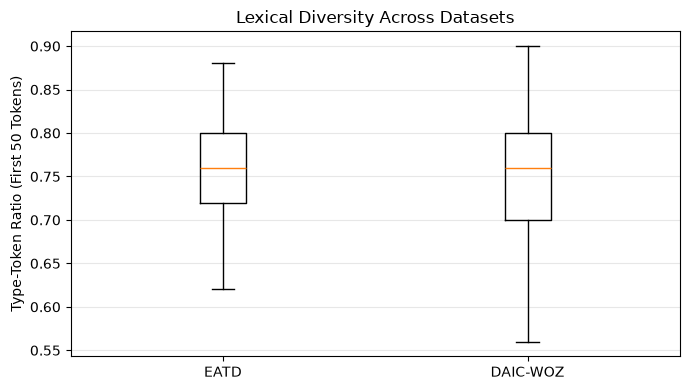

In [5]:

import numpy as np
import matplotlib.pyplot as plt

def calculate_diversity(text):
    tokens = tokenize(text)

    if not tokens:
        return pd.Series({
            "n_tokens": 0,
            "ttr": np.nan,
            "ttr_50": np.nan
        })

    ttr = len(set(tokens)) / len(tokens)

    ttr_50 = (
        len(set(tokens[:50])) / 50
        if len(tokens) >= 50 else np.nan
    )

    return pd.Series({
        "n_tokens": len(tokens),
        "ttr": ttr,
        "ttr_50": ttr_50
    })

eatd_div = eatd["text"].apply(calculate_diversity)
daic_div = daic["text"].apply(calculate_diversity)

diversity_summary = pd.DataFrame({
    "Dataset": ["EATD", "DAIC-WOZ"],
    "Mean TTR": [
        eatd_div["ttr"].mean(),
        daic_div["ttr"].mean()
    ],
    "Mean TTR (50 tokens)": [
        eatd_div["ttr_50"].mean(),
        daic_div["ttr_50"].mean()
    ],
    "Eligible Texts (50 tokens)": [
        eatd_div["ttr_50"].notna().sum(),
        daic_div["ttr_50"].notna().sum()
    ]
})

display(diversity_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    [
        eatd_div["ttr_50"].dropna(),
        daic_div["ttr_50"].dropna()
    ],
    tick_labels=["EATD", "DAIC-WOZ"]
)

ax.set_title("Lexical Diversity Across Datasets")
ax.set_ylabel("Type-Token Ratio (First 50 Tokens)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("lexical_diversity_comparison.png", dpi=300)
plt.show()


,Dataset,Mean Words,Median Words,Min Words,Max Words
0,EATD,98.38,70.5,10,430
1,DAIC-WOZ,1443.78,1249.0,165,4550


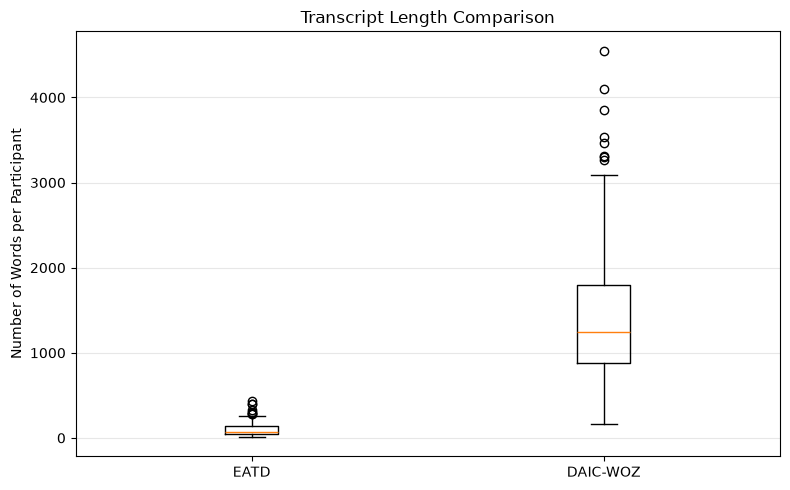

In [7]:

import matplotlib.pyplot as plt
import numpy as np

eatd_lengths = eatd["text"].fillna("").apply(
    lambda x: len(tokenize(x))
)

daic_lengths = daic["text"].fillna("").apply(
    lambda x: len(tokenize(x))
)

length_summary = pd.DataFrame({
    "Dataset": ["EATD", "DAIC-WOZ"],
    "Mean Words": [
        eatd_lengths.mean(),
        daic_lengths.mean()
    ],
    "Median Words": [
        eatd_lengths.median(),
        daic_lengths.median()
    ],
    "Min Words": [
        eatd_lengths.min(),
        daic_lengths.min()
    ],
    "Max Words": [
        eatd_lengths.max(),
        daic_lengths.max()
    ]
})

display(length_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [eatd_lengths, daic_lengths],
    tick_labels=["EATD", "DAIC-WOZ"]
)

ax.set_title("Transcript Length Comparison")
ax.set_ylabel("Number of Words per Participant")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("transcript_length_comparison.png", dpi=300)
plt.show()


In [10]:

for name, df in [("EATD", eatd), ("DAIC-WOZ", daic)]:
    texts = df["text"].fillna("").astype(str)

    punctuation = texts.apply(
        lambda x: sum(x.count(p) for p in [".", "!", "?"])
    )

    print(f"\n{name}")
    print("Mean sentence-ending punctuation:",
          round(punctuation.mean(), 2))
    print("Texts without sentence-ending punctuation:",
          int((punctuation == 0).sum()))



EATD
Mean sentence-ending punctuation: 4.31
Texts without sentence-ending punctuation: 0

DAIC-WOZ
Mean sentence-ending punctuation: 0.02
Texts without sentence-ending punctuation: 188


,Dataset,Unit,Count,Mean Words,Median Words
0,EATD,Sentence,703,22.67,18.0
1,DAIC-WOZ,Utterance,31350,8.71,6.0


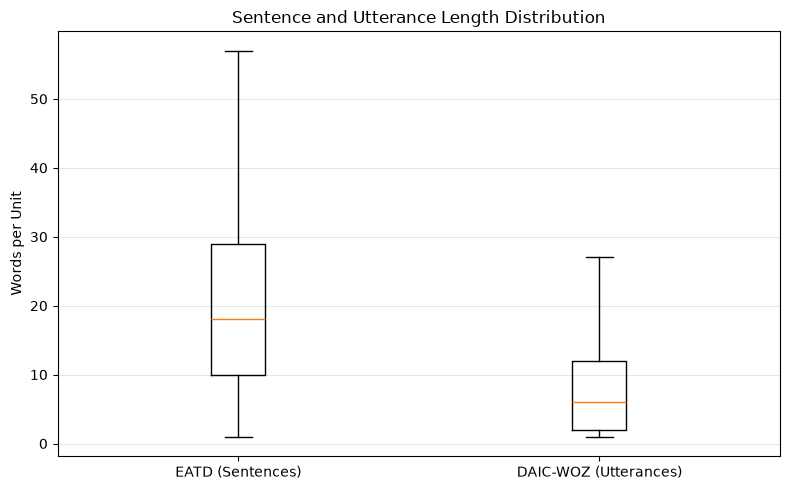

In [12]:

import re
import os
import pandas as pd
import matplotlib.pyplot as plt

# EATD: split by sentence-ending punctuation
eatd_sentence_lengths = []

for text in eatd["text"].dropna():
    sentences = re.split(r"[.!?]+", str(text))

    for sentence in sentences:
        n = len(tokenize(sentence))
        if n > 0:
            eatd_sentence_lengths.append(n)

# DAIC-WOZ: use participant utterances
daic_utterance_lengths = []

for participant_id in daic["id"]:
    path = f"all_csv_nlp/{participant_id}_TRANSCRIPT.csv"

    if not os.path.exists(path):
        continue

    if int(participant_id) == 440:
        df = pd.read_csv(path, encoding="utf-8-sig")
        values = df["Text"].dropna()
    else:
        df = pd.read_csv(path, sep="\t")
        df.columns = df.columns.str.strip()

        if not {"speaker", "value"}.issubset(df.columns):
            continue

        values = df.loc[
            df["speaker"].astype(str).str.strip() == "Participant",
            "value"
        ].dropna()

    for value in values:
        cleaned = re.sub(r"<[^>]*>", " ", str(value))
        n = len(tokenize(cleaned))

        if n > 0:
            daic_utterance_lengths.append(n)

# Summary statistics
length_stats = pd.DataFrame({
    "Dataset": ["EATD", "DAIC-WOZ"],
    "Unit": ["Sentence", "Utterance"],
    "Count": [
        len(eatd_sentence_lengths),
        len(daic_utterance_lengths)
    ],
    "Mean Words": [
        pd.Series(eatd_sentence_lengths).mean(),
        pd.Series(daic_utterance_lengths).mean()
    ],
    "Median Words": [
        pd.Series(eatd_sentence_lengths).median(),
        pd.Series(daic_utterance_lengths).median()
    ]
})

display(length_stats.round(2))

# Boxplot
fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [eatd_sentence_lengths, daic_utterance_lengths],
    tick_labels=["EATD (Sentences)", "DAIC-WOZ (Utterances)"],
    showfliers=False
)

ax.set_title("Sentence and Utterance Length Distribution")
ax.set_ylabel("Words per Unit")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("sentence_utterance_length.png", dpi=300)
plt.show()


,Dataset,Pronoun Group,Count,Per 1000 Tokens
0,EATD,First Person Singular,997,62.56
1,EATD,First Person Plural,33,2.07
2,EATD,Second Person,134,8.41
3,EATD,Third Person,251,15.75
4,DAIC-WOZ,First Person Singular,24111,88.36
5,DAIC-WOZ,First Person Plural,1110,4.07
6,DAIC-WOZ,Second Person,4651,17.04
7,DAIC-WOZ,Third Person,3492,12.80


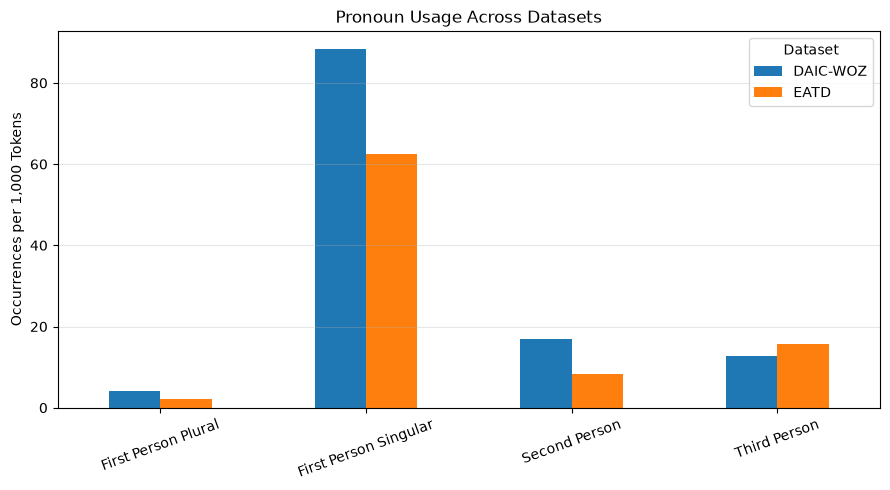

In [13]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

pronoun_groups = {
    "First Person Singular": {
        "i", "me", "my", "mine", "myself"
    },
    "First Person Plural": {
        "we", "us", "our", "ours", "ourselves"
    },
    "Second Person": {
        "you", "your", "yours", "yourself", "yourselves"
    },
    "Third Person": {
        "he", "him", "his", "himself",
        "she", "her", "hers", "herself",
        "they", "them", "their", "theirs", "themselves"
    }
}

def pronoun_stats(df, dataset_name):
    all_tokens = []

    for text in df["text"].fillna(""):
        all_tokens.extend(tokenize(text))

    counts = Counter(all_tokens)
    total = len(all_tokens)
    results = []

    for group, words in pronoun_groups.items():
        count = sum(counts[word] for word in words)

        results.append({
            "Dataset": dataset_name,
            "Pronoun Group": group,
            "Count": count,
            "Per 1000 Tokens": count / total * 1000
        })

    return results

pronoun_results = pd.DataFrame(
    pronoun_stats(eatd, "EATD")
    + pronoun_stats(daic, "DAIC-WOZ")
)

display(pronoun_results.round(2))

pivot = pronoun_results.pivot(
    index="Pronoun Group",
    columns="Dataset",
    values="Per 1000 Tokens"
)

ax = pivot.plot(kind="bar", figsize=(9, 5))

ax.set_title("Pronoun Usage Across Datasets")
ax.set_ylabel("Occurrences per 1,000 Tokens")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("pronoun_usage_comparison.png", dpi=300)
plt.show()


,Dataset,Emotion,Count,Per 1000 Tokens
0,EATD,Sadness,27,1.69
1,EATD,Anxiety,11,0.69
2,EATD,Anger,29,1.82
3,EATD,Positive Emotion,81,5.08
4,DAIC-WOZ,Sadness,146,0.54
5,DAIC-WOZ,Anxiety,249,0.91
6,DAIC-WOZ,Anger,305,1.12
7,DAIC-WOZ,Positive Emotion,967,3.54


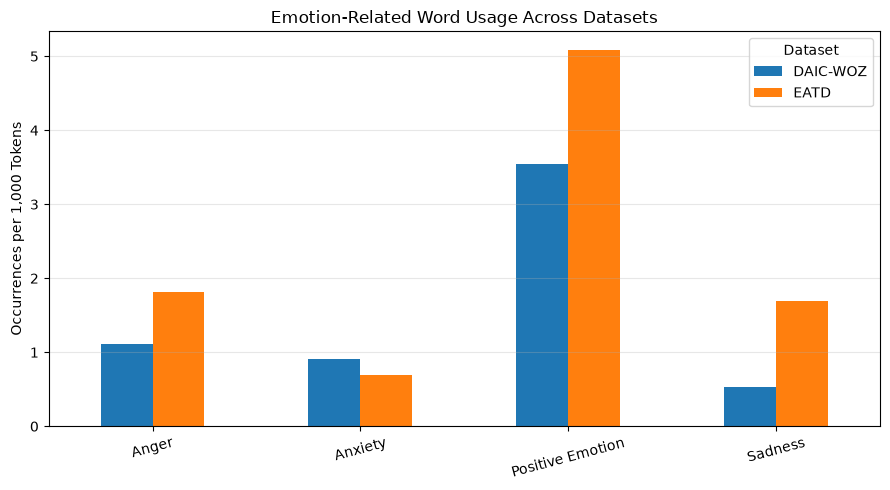

In [14]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

emotion_words = {
    "Sadness": {
        "sad", "unhappy", "depressed", "lonely",
        "hopeless", "miserable", "grief", "cry",
        "crying", "worthless"
    },
    "Anxiety": {
        "anxious", "worried", "worry", "nervous",
        "afraid", "fear", "scared", "panic",
        "stress", "stressed"
    },
    "Anger": {
        "angry", "mad", "furious", "frustrated",
        "annoyed", "hate", "irritated"
    },
    "Positive Emotion": {
        "happy", "joy", "excited", "love",
        "glad", "hopeful", "grateful",
        "enjoy", "enjoyed", "pleased"
    }
}

def emotion_stats(df, dataset_name):
    tokens = []

    for text in df["text"].fillna(""):
        tokens.extend(tokenize(text))

    counts = Counter(tokens)
    total = len(tokens)
    results = []

    for emotion, words in emotion_words.items():
        count = sum(counts[word] for word in words)

        results.append({
            "Dataset": dataset_name,
            "Emotion": emotion,
            "Count": count,
            "Per 1000 Tokens": (
                count / total * 1000 if total else 0
            )
        })

    return results

emotion_results = pd.DataFrame(
    emotion_stats(eatd, "EATD")
    + emotion_stats(daic, "DAIC-WOZ")
)

display(emotion_results.round(2))

pivot = emotion_results.pivot(
    index="Emotion",
    columns="Dataset",
    values="Per 1000 Tokens"
)

ax = pivot.plot(kind="bar", figsize=(9, 5))

ax.set_title("Emotion-Related Word Usage Across Datasets")
ax.set_ylabel("Occurrences per 1,000 Tokens")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("emotion_word_comparison.png", dpi=300)
plt.show()


In [17]:

from sentence_transformers import SentenceTransformer
import numpy as np

model = SentenceTransformer("all-MiniLM-L6-v2")

def chunk_text(text, max_tokens=200):
    token_ids = model.tokenizer.encode(
        str(text),
        add_special_tokens=False
    )

    chunks = []
    for i in range(0, len(token_ids), max_tokens):
        chunk = model.tokenizer.decode(
            token_ids[i:i + max_tokens],
            skip_special_tokens=True
        )
        chunks.append(chunk)

    return chunks if chunks else [""]

def get_embeddings(texts):
    all_chunks = []
    boundaries = [0]

    for text in texts:
        chunks = chunk_text(text)
        all_chunks.extend(chunks)
        boundaries.append(len(all_chunks))

    chunk_embeddings = model.encode(
        all_chunks,
        batch_size=16,
        show_progress_bar=True,
        convert_to_numpy=True
    )

    embeddings = []

    for i in range(len(texts)):
        start = boundaries[i]
        end = boundaries[i + 1]
        embeddings.append(
            chunk_embeddings[start:end].mean(axis=0)
        )

    return np.vstack(embeddings)

eatd_texts = eatd["text"].fillna("").astype(str).tolist()
daic_texts = daic["text"].fillna("").astype(str).tolist()

eatd_embeddings = get_embeddings(eatd_texts)
daic_embeddings = get_embeddings(daic_texts)

print("EATD embeddings:", eatd_embeddings.shape)
print("DAIC-WOZ embeddings:", daic_embeddings.shape)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13350.64it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (371 > 256). Running this sequence through the model will result in indexing errors
Batches: 100%|██████████| 102/102 [00:02<00:00, 42.76it/s]

EATD embeddings: (162, 384)
DAIC-WOZ embeddings: (189, 384)


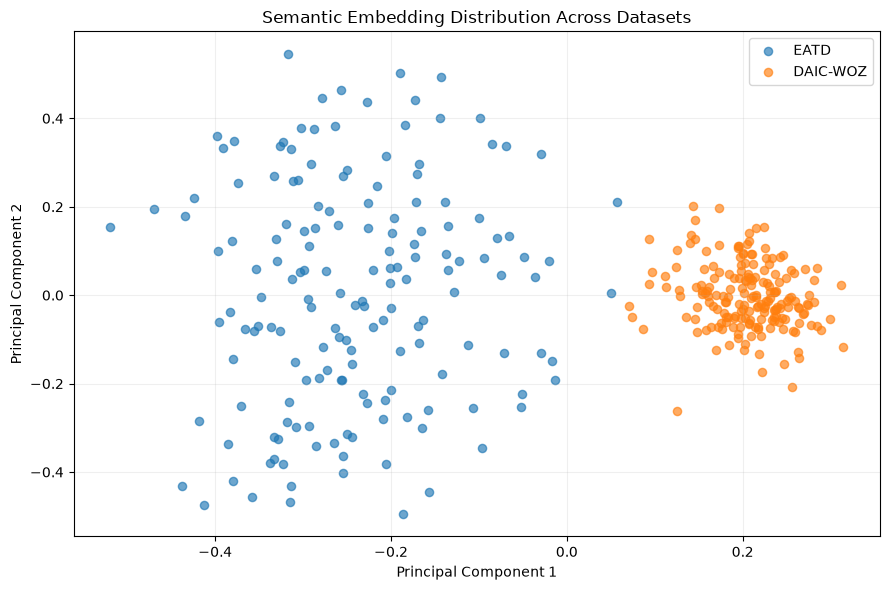

Explained variance: [0.1209 0.0698]


In [18]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

all_embeddings = np.vstack([
    eatd_embeddings,
    daic_embeddings
])

pca = PCA(n_components=2)
reduced = pca.fit_transform(all_embeddings)

n_eatd = len(eatd_embeddings)

plt.figure(figsize=(9, 6))

plt.scatter(
    reduced[:n_eatd, 0],
    reduced[:n_eatd, 1],
    label="EATD",
    alpha=0.65,
    s=35
)

plt.scatter(
    reduced[n_eatd:, 0],
    reduced[n_eatd:, 1],
    label="DAIC-WOZ",
    alpha=0.65,
    s=35
)

plt.title("Semantic Embedding Distribution Across Datasets")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("semantic_embedding_pca.png", dpi=300)
plt.show()

print(
    "Explained variance:",
    pca.explained_variance_ratio_.round(4)
)


Batches: 100%|██████████| 12/12 [00:00<00:00, 114.05it/s]


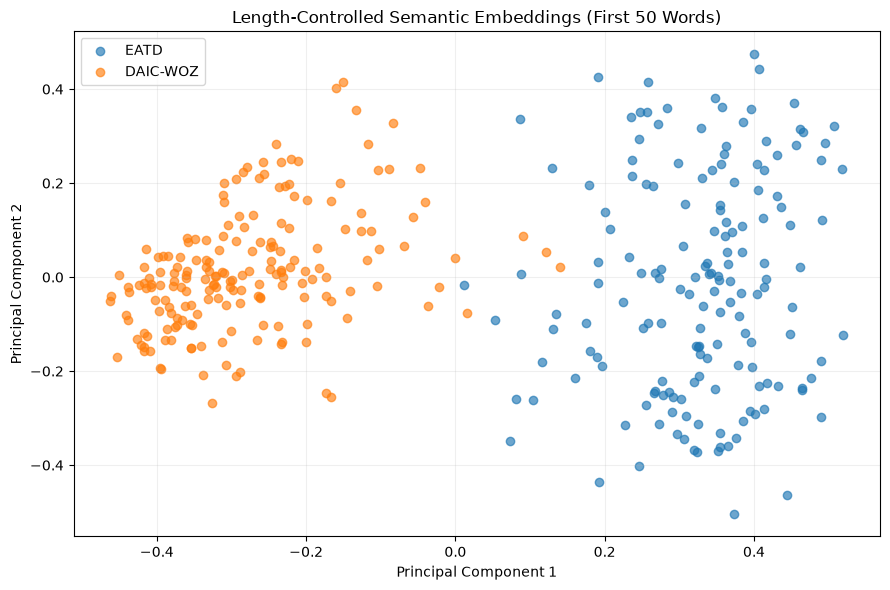

Explained variance: [0.1343 0.0439]


In [19]:

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

def first_n_words(text, n=50):
    return " ".join(str(text).split()[:n])

eatd_short = [
    first_n_words(text)
    for text in eatd["text"].fillna("")
]

daic_short = [
    first_n_words(text)
    for text in daic["text"].fillna("")
]

eatd_short_emb = model.encode(
    eatd_short,
    batch_size=16,
    show_progress_bar=True
)

daic_short_emb = model.encode(
    daic_short,
    batch_size=16,
    show_progress_bar=True
)

combined = np.vstack([
    eatd_short_emb,
    daic_short_emb
])

pca_short = PCA(n_components=2)
reduced_short = pca_short.fit_transform(combined)

n_eatd = len(eatd_short_emb)

plt.figure(figsize=(9, 6))

plt.scatter(
    reduced_short[:n_eatd, 0],
    reduced_short[:n_eatd, 1],
    label="EATD",
    alpha=0.65
)

plt.scatter(
    reduced_short[n_eatd:, 0],
    reduced_short[n_eatd:, 1],
    label="DAIC-WOZ",
    alpha=0.65
)

plt.title("Length-Controlled Semantic Embeddings (First 50 Words)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("semantic_embedding_pca_50words.png", dpi=300)
plt.show()

print(
    "Explained variance:",
    pca_short.explained_variance_ratio_.round(4)
)


In [24]:

import pandas as pd
import os

path = "data/daicwoz.csv"

if os.path.exists(path):
    team_daic = pd.read_csv(path)

    print("Shape:", team_daic.shape)
    print("Columns:", team_daic.columns.tolist())
    print("Unique participants:", team_daic["id"].nunique())
    print("Participant 440 included:",
          440 in team_daic["id"].values)

    print("\nSplit distribution:")
    print(team_daic["split"].value_counts())

    print("\nLabel distribution:")
    print(team_daic["label"].value_counts())

    display(team_daic.head())
else:
    print("File not found:", path)


Shape: (189, 5)
Columns: ['id', 'label', 'split', 'text', 'n_words']
Unique participants: 189
Participant 440 included: True

Split distribution:
split
train    107
test      47
dev       35
Name: count, dtype: int64

Label distribution:
label
0    133
1     56
Name: count, dtype: int64


,id,label,split,text,n_words
0,303,0,train,okay how 'bout yourself here in california yea...,1960
1,304,0,train,i'm doing good um from los angeles california ...,976
2,305,0,train,i'm doing alright uh originally i'm from calif...,3321
3,310,0,train,yes it's okay fine i live in hollywood uh seat...,1069
4,312,0,train,yes fine how about you here yes the weather we...,1192


In [26]:
import pandas as pd

team_daic = pd.read_csv("data/daicwoz.csv")

print("Shape:", team_daic.shape)
print("Columns:", team_daic.columns.tolist())
print("Unique participants:", team_daic["id"].nunique())
print("Participant 440 included:", 440 in team_daic["id"].values)

print("\nSplit distribution:")
print(team_daic["split"].value_counts())

print("\nLabel distribution:")
print(team_daic["label"].value_counts())

print("\nMissing values:")
print(team_daic.isnull().sum())

Shape: (189, 5)
Columns: ['id', 'label', 'split', 'text', 'n_words']
Unique participants: 189
Participant 440 included: True

Split distribution:
split
train    107
test      47
dev       35
Name: count, dtype: int64

Label distribution:
label
0    133
1     56
Name: count, dtype: int64

Missing values:
id         0
label      0
split      0
text       0
n_words    0
dtype: int64
